# Sentiment Analysis of IMDB Movie Reviews Using a Bidirectional LSTM

**Student Name:** Swapnil Santosh Akhade  
**PRN:** 202401110002  
**Dept:** AIML  
**Course:** GenAI  

## Abstract

This experiment implements a deep-learning-based sentiment analysis system for classifying IMDB movie reviews as positive or negative. The primary model is a Bidirectional Long Short-Term Memory (BiLSTM) network implemented using PyTorch. The workflow includes text preprocessing, exploratory data analysis, vocabulary construction, model training, performance evaluation, and comparison with alternative classification models.

The experiment also examines misclassified examples and visualizes selected learned word embeddings. Quantitative results and generated visualizations are produced when the notebook is executed.

## Aim

To develop and evaluate a Bidirectional LSTM model for binary sentiment classification of movie reviews.

## Objectives

1. Load and explore the IMDB movie-review dataset.
2. Preprocess text data and convert reviews into numerical sequences.
3. Implement and train a Bidirectional LSTM classifier.
4. Evaluate the classifier using standard classification metrics.
5. Compare the BiLSTM model with a unidirectional LSTM and a TF-IDF-based Logistic Regression model.
6. Analyse classification errors and visualize learned word embeddings.

## Dataset and Tools

- **Dataset:** Stanford IMDB movie-review dataset, containing labelled positive and negative reviews.
- **Programming language:** Python
- **Deep-learning framework:** PyTorch
- **Data processing and evaluation:** NumPy, Pandas, and scikit-learn
- **Visualization:** Matplotlib
- **Execution environment:** Google Colab (GPU runtime recommended)

## Execution Instructions

Open this notebook in Google Colab. A GPU runtime is recommended because the notebook trains recurrent neural-network models. Execute the cells in sequence from top to bottom. The dataset is loaded through the Hugging Face Datasets library, so a separate dataset upload is not required.

The generated plots, evaluation reports, CSV files, and saved model artifacts are stored in `/content/results/`. The final section packages these files into `results.zip`.


## 1. Environment Setup and Hyperparameter Configuration

This section imports the required Python libraries, initializes the random seeds for reproducibility, selects the available execution device (GPU or CPU), and creates the directory used to store experimental outputs.

The model configuration includes the vocabulary limit, maximum review length, embedding dimension, LSTM hidden size, dropout rate, batch size, number of training epochs, and learning rate. These values define the initial experimental setup.


In [1]:
# ============================================================
# CELL 1: Setup & Imports
# ============================================================
import os, re, time, random, warnings, zipfile, shutil
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report,
                             roc_curve)
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings('ignore')

SEED = 2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

# Create output directory
OUTPUT_DIR = '/content/results'
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Outputs will be saved to: {OUTPUT_DIR}")

# Hyperparameters
MAX_VOCAB = 20000
MAX_LEN   = 300
EMB_DIM   = 128
HIDDEN    = 128
DROPOUT   = 0.4
BATCH     = 64
EPOCHS    = 8
LR        = 1e-3


Device: cuda
Outputs will be saved to: /content/results


## 2. Dependency Installation and Dataset Loading

The Hugging Face Datasets library is installed and used to load the Stanford IMDB dataset. The provided training partition is divided later into training and validation subsets, while the original test partition is retained for final evaluation.

Each review has a binary sentiment label: `0` represents a negative review and `1` represents a positive review.


In [2]:
# ============================================================
# CELL 2: Install dependencies & Load IMDB dataset
# ============================================================
!pip install -q datasets

from datasets import load_dataset
ds = load_dataset('stanfordnlp/imdb')
train_val_texts = ds['train']['text']
train_val_labels = np.array(ds['train']['label'])
test_texts = ds['test']['text']
test_labels = np.array(ds['test']['label'])

print(f"Train+val: {len(train_val_texts)} | Test: {len(test_texts)}")
print(f"Example: {train_val_texts[0][:200]}...")


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Train+val: 25000 | Test: 25000
Example: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ev...


## 3. Text Preprocessing and Exploratory Data Analysis

A text-cleaning function converts reviews to lowercase, removes HTML line-break tags, and tokenizes the text into words and selected punctuation marks.

Exploratory analysis is performed to examine the class distribution and review-length distribution. The generated plots help describe the dataset and show how the selected maximum sequence length relates to review lengths.


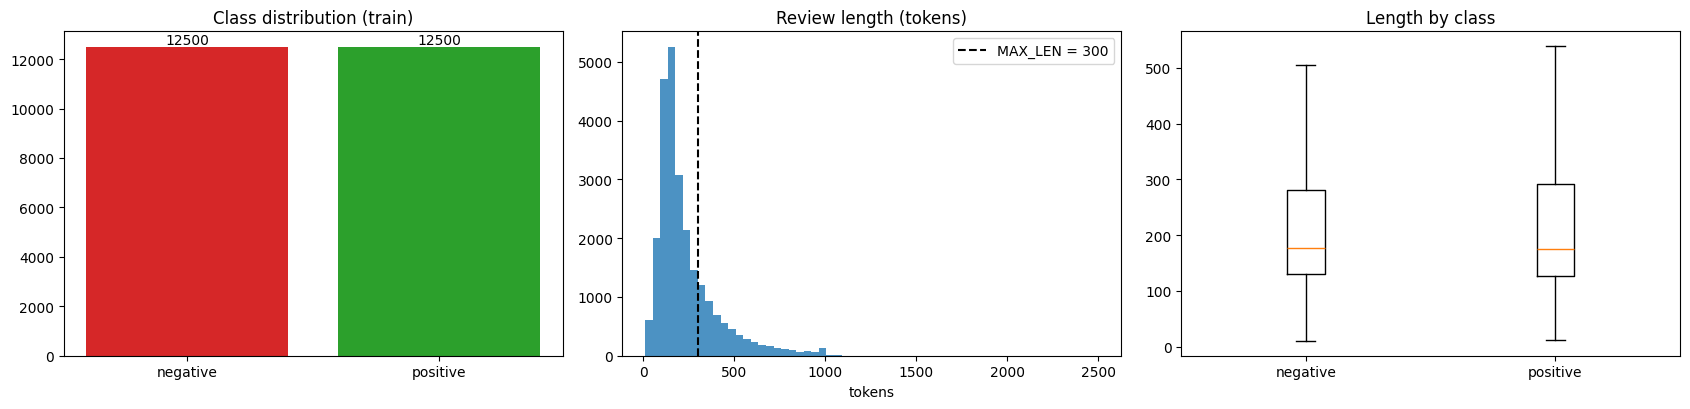

Mean length = 235 | median = 176 | 77% not truncated


In [3]:
# ============================================================
# CELL 3: Text cleaning & EDA
# ============================================================
def clean(text):
    text = re.sub(r'<br\s*/?>', ' ', text.lower())
    return re.findall(r"[a-z0-9']+|[!?]", text)

lengths = np.array([len(clean(t)) for t in train_val_texts])
labels_np = np.array(train_val_labels)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
cnt = (pd.Series(labels_np).map({0: 'negative', 1: 'positive'})
      .value_counts().reindex(['negative', 'positive']))
ax[0].bar(cnt.index, cnt.values, color=['tab:red', 'tab:green'])
ax[0].set_title('Class distribution (train)')
for i, v in enumerate(cnt.values): ax[0].text(i, v + 100, str(v), ha='center')

ax[1].hist(lengths, bins=60, color='tab:blue', alpha=.8)
ax[1].axvline(MAX_LEN, color='k', ls='--', label=f'MAX_LEN = {MAX_LEN}')
ax[1].set_title('Review length (tokens)')
ax[1].set_xlabel('tokens'); ax[1].legend()

ax[2].boxplot([lengths[labels_np == 0], lengths[labels_np == 1]],
              labels=['negative', 'positive'], showfliers=False)
ax[2].set_title('Length by class')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/eda_overview.png', dpi=130)
plt.show()

print(f'Mean length = {lengths.mean():.0f} | median = {np.median(lengths):.0f} | '
      f'{(lengths <= MAX_LEN).mean()*100:.0f}% not truncated')


## 4. Dataset Splitting, Vocabulary Construction, and Sequence Encoding

The training partition is divided into training and validation subsets using stratified sampling. This preserves the approximate class proportions in both subsets.

The vocabulary is constructed using only the training reviews. Two reserved tokens are used: `<pad>` for sequence padding and `<unk>` for words not present in the vocabulary. Reviews are converted into token indices, truncated to the configured maximum length, and padded to a common length to support batch processing.

The resulting tensors are loaded through PyTorch DataLoaders for model training and validation.


In [4]:
# ============================================================
# CELL 4: Preprocessing (split, vocab, encode, pad)
# ============================================================
tr_texts, va_texts, tr_y, va_y = train_test_split(
    train_val_texts, train_val_labels, test_size=0.1,
    stratify=train_val_labels, random_state=SEED)
print(f'train = {len(tr_texts)} | val = {len(va_texts)} | test = {len(test_texts)}')

counter = Counter(w for t in tr_texts for w in clean(t))
itos = ['<pad>', '<unk>'] + [w for w, _ in counter.most_common(MAX_VOCAB - 2)]
stoi = {w: i for i, w in enumerate(itos)}
print(f'Vocab size: {len(itos)}')

def encode(texts, labels):
    ids = [[stoi.get(w, 1) for w in clean(t)][:MAX_LEN] for t in texts]
    lens = torch.tensor([max(len(s), 1) for s in ids])
    X = torch.zeros(len(ids), MAX_LEN, dtype=torch.long)
    for i, s in enumerate(ids): X[i, :len(s)] = torch.tensor(s)
    return X, lens, torch.tensor(labels, dtype=torch.float32)

Xtr, Ltr, ytr = encode(tr_texts, tr_y)
Xva, Lva, yva = encode(va_texts, va_y)
Xte, Lte, yte = encode(test_texts, test_labels)

train_loader = DataLoader(TensorDataset(Xtr, Ltr, ytr), batch_size=BATCH, shuffle=True)
val_loader   = DataLoader(TensorDataset(Xva, Lva, yva), batch_size=256)


train = 22500 | val = 2500 | test = 25000
Vocab size: 20000


## 5. Bidirectional LSTM Model Architecture

This section defines the sentiment-classification network using PyTorch. The architecture consists of an embedding layer, a two-layer bidirectional LSTM, dropout regularization, and a fully connected output layer.

The bidirectional LSTM processes each review in both forward and backward directions. Its final hidden representations are concatenated and passed to the output layer, which produces a logit for binary sentiment classification.


In [5]:
# ============================================================
# CELL 5: Model definition (BiLSTM)
# ============================================================
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim=EMB_DIM, hidden=HIDDEN,
                 layers=2, bidirectional=True, dropout=DROPOUT):
        super().__init__()
        self.bidirectional = bidirectional
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.lstm = nn.LSTM(emb_dim, hidden, num_layers=layers, batch_first=True,
                            bidirectional=bidirectional,
                            dropout=dropout if layers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden * (2 if bidirectional else 1), 1)

    def forward(self, x, lengths):
        emb = self.dropout(self.embedding(x))
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed)
        h = torch.cat([h[-2], h[-1]], dim=1) if self.bidirectional else h[-1]
        return self.fc(self.dropout(h)).squeeze(1)

model = LSTMClassifier(len(itos)).to(device)
print(model)
print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')


LSTMClassifier(
  (embedding): Embedding(20000, 128, padding_idx=0)
  (lstm): LSTM(128, 128, num_layers=2, batch_first=True, dropout=0.4, bidirectional=True)
  (dropout): Dropout(p=0.4, inplace=False)
  (fc): Linear(in_features=256, out_features=1, bias=True)
)
Parameters: 3,219,713


## 6. Model Training and Early Stopping

The model is trained using binary cross-entropy with logits as the loss function and the Adam optimizer for parameter updates. Gradient clipping is applied to limit excessively large gradients.

Training and validation loss and accuracy are calculated after each epoch. The model parameters with the lowest validation loss are retained. Early stopping is used to stop training when the validation loss does not improve for the configured number of consecutive epochs.


In [6]:
# ============================================================
# CELL 6: Training loop with early stopping
# ============================================================
criterion = nn.BCEWithLogitsLoss()

def run_epoch(model, loader, opt=None):
    train = opt is not None; model.train(train)
    tot_loss = correct = n = 0
    with torch.set_grad_enabled(train):
        for x, l, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x, l); loss = criterion(logits, y)
            if train:
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tot_loss += loss.item() * len(y)
            correct += ((logits > 0).float() == y).sum().item(); n += len(y)
    return tot_loss / n, correct / n

def train_model(model, name, epochs=EPOCHS, patience=3):
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best, best_state, bad, t0 = 1e9, None, 0, time.time()
    for ep in range(1, epochs + 1):
        trl, tra = run_epoch(model, train_loader, opt)
        val, vaa = run_epoch(model, val_loader)
        for k, v in zip(hist, [trl, val, tra, vaa]): hist[k].append(v)
        flag = ''
        if val < best:
            best, bad, flag = val, 0, ' *best*'
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else: bad += 1
        print(f'[{name}] epoch {ep}/{epochs} | '
              f'train loss {trl:.4f} acc {tra:.4f} | '
              f'val loss {val:.4f} acc {vaa:.4f} | {time.time()-t0:.0f}s{flag}')
        if bad >= patience: print('Early stopping.'); break
    model.load_state_dict(best_state)
    return hist

hist_main = train_model(model, 'BiLSTM-2L')


[BiLSTM-2L] epoch 1/8 | train loss 0.6278 acc 0.6356 | val loss 0.6334 acc 0.6832 | 19s *best*
[BiLSTM-2L] epoch 2/8 | train loss 0.5397 acc 0.7282 | val loss 0.4780 acc 0.7908 | 36s *best*
[BiLSTM-2L] epoch 3/8 | train loss 0.4272 acc 0.8066 | val loss 0.3826 acc 0.8420 | 53s *best*
[BiLSTM-2L] epoch 4/8 | train loss 0.3689 acc 0.8431 | val loss 0.4117 acc 0.8532 | 69s
[BiLSTM-2L] epoch 5/8 | train loss 0.3173 acc 0.8677 | val loss 0.4960 acc 0.8184 | 87s
[BiLSTM-2L] epoch 6/8 | train loss 0.2920 acc 0.8771 | val loss 0.3224 acc 0.8812 | 103s *best*
[BiLSTM-2L] epoch 7/8 | train loss 0.2460 acc 0.9013 | val loss 0.3026 acc 0.8900 | 120s *best*
[BiLSTM-2L] epoch 8/8 | train loss 0.2278 acc 0.9086 | val loss 0.2756 acc 0.8912 | 138s *best*


## 7. Training and Validation Performance

The training history is visualized using separate plots for loss and accuracy. The curves show how the model performs on the training and validation subsets across epochs.

These plots can be used to examine convergence and identify possible differences between training and validation behaviour.


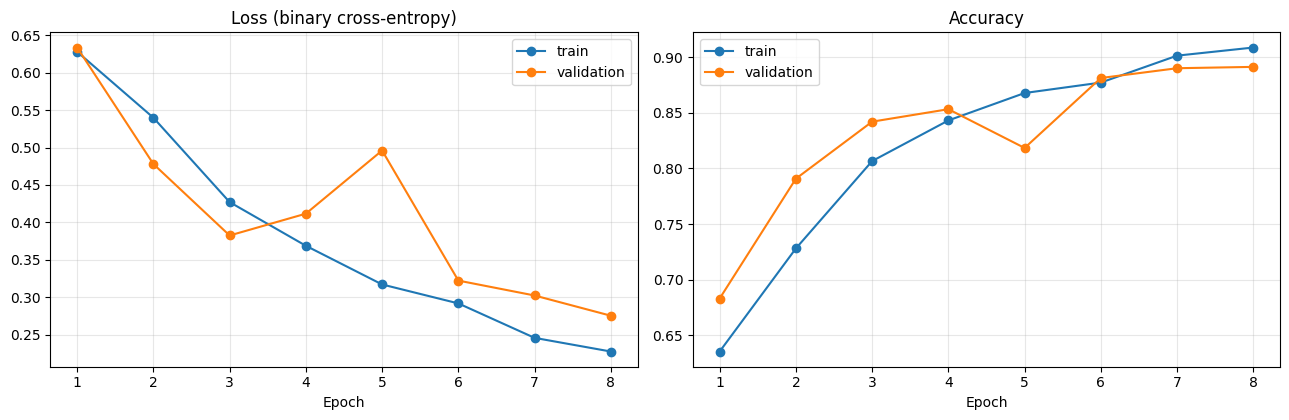

In [7]:
# ============================================================
# CELL 7: Training curves
# ============================================================
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
e = np.arange(1, len(hist_main['train_loss']) + 1)
ax[0].plot(e, hist_main['train_loss'], 'o-', label='train')
ax[0].plot(e, hist_main['val_loss'], 'o-', label='validation')
ax[0].set_title('Loss (binary cross-entropy)'); ax[0].set_xlabel('Epoch')
ax[1].plot(e, hist_main['train_acc'], 'o-', label='train')
ax[1].plot(e, hist_main['val_acc'], 'o-', label='validation')
ax[1].set_title('Accuracy'); ax[1].set_xlabel('Epoch')
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/training_curves.png', dpi=130)
plt.show()


## 8. Evaluation of the BiLSTM Model

The trained BiLSTM model is evaluated on the held-out test partition. Predicted probabilities are converted into class labels using a threshold of `0.5`.

The evaluation includes accuracy, precision, recall, F1-score, and ROC-AUC. A classification report, count-based confusion matrix, normalized confusion matrix, and ROC curve are generated and saved to the output directory. The test partition is kept separate from model training and validation.


              precision    recall  f1-score   support

    negative     0.8565    0.8978    0.8767     12500
    positive     0.8926    0.8496    0.8706     12500

    accuracy                         0.8737     25000
   macro avg     0.8745    0.8737    0.8736     25000
weighted avg     0.8745    0.8737    0.8736     25000



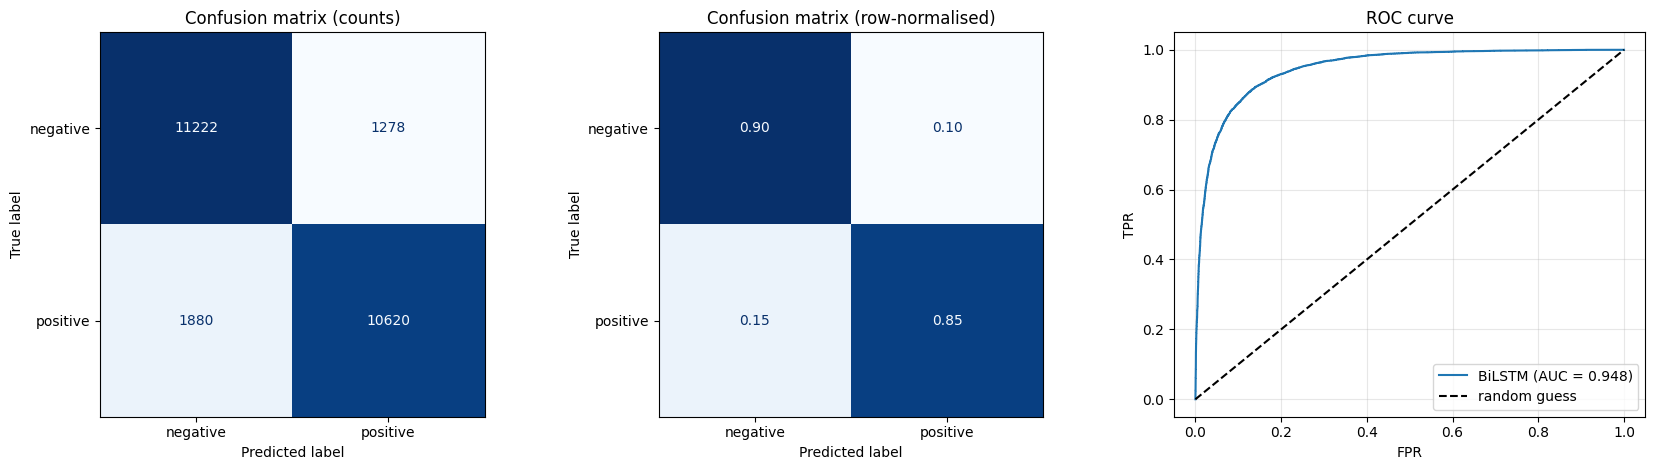

TP=10620, TN=11222, FP=1278, FN=1880


In [8]:
# ============================================================
# CELL 8: Evaluation on test set
# ============================================================
@torch.no_grad()
def predict_proba(model, X, L, bs=512):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        out.append(torch.sigmoid(model(X[i:i + bs].to(device), L[i:i + bs])).cpu())
    return torch.cat(out).numpy()

def metrics(y_true, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {'Accuracy': accuracy_score(y_true, pred),
            'Precision': precision_score(y_true, pred, zero_division=0),
            'Recall': recall_score(y_true, pred),
            'F1-score': f1_score(y_true, pred, zero_division=0),
            'ROC-AUC': roc_auc_score(y_true, prob)}

prob_main = predict_proba(model, Xte, Lte)
pred_main = (prob_main >= 0.5).astype(int)
res_main = metrics(test_labels, prob_main)

# Save classification report
report = classification_report(test_labels, pred_main,
                               target_names=['negative', 'positive'], digits=4)
with open(f'{OUTPUT_DIR}/classification_report.txt', 'w') as f:
    f.write(report)
print(report)

# Confusion matrix + ROC curve
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
cm = confusion_matrix(test_labels, pred_main)
ConfusionMatrixDisplay(cm, display_labels=['negative', 'positive']).plot(
    ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title('Confusion matrix (counts)')
ConfusionMatrixDisplay(confusion_matrix(test_labels, pred_main, normalize='true'),
                       display_labels=['negative', 'positive']).plot(
    ax=ax[1], cmap='Blues', colorbar=False, values_format='.2f')
ax[1].set_title('Confusion matrix (row-normalised)')
fpr, tpr, _ = roc_curve(test_labels, prob_main)
ax[2].plot(fpr, tpr, label=f'BiLSTM (AUC = {res_main["ROC-AUC"]:.3f})')
ax[2].plot([0, 1], [0, 1], 'k--', label='random guess')
ax[2].set_xlabel('FPR'); ax[2].set_ylabel('TPR')
ax[2].set_title('ROC curve'); ax[2].legend(); ax[2].grid(alpha=.3)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/evaluation.png', dpi=130)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'TP={tp}, TN={tn}, FP={fp}, FN={fn}')

# Save metrics table
pd.DataFrame(res_main, index=['BiLSTM (2 layers)']).round(4).to_csv(
    f'{OUTPUT_DIR}/test_metrics.csv')


## 9. Comparative Evaluation with Baseline Models

The BiLSTM model is compared with two baseline approaches:

1. **Unidirectional LSTM:** A one-layer LSTM that processes the review sequence in a single direction.
2. **TF-IDF with Logistic Regression:** A traditional machine-learning approach using unigram and bigram TF-IDF features followed by Logistic Regression.

All three approaches are evaluated on the same held-out test partition using the same set of metrics. A comparison table and metric/ROC plots are generated to support the analysis.


[LSTM-1L-uni] epoch 1/8 | train loss 0.6514 acc 0.6125 | val loss 0.5861 acc 0.7040 | 6s *best*
[LSTM-1L-uni] epoch 2/8 | train loss 0.5486 acc 0.7343 | val loss 0.5951 acc 0.7096 | 13s
[LSTM-1L-uni] epoch 3/8 | train loss 0.4649 acc 0.7943 | val loss 0.5118 acc 0.7848 | 19s *best*
[LSTM-1L-uni] epoch 4/8 | train loss 0.3936 acc 0.8339 | val loss 0.5192 acc 0.7892 | 26s
[LSTM-1L-uni] epoch 5/8 | train loss 0.3429 acc 0.8587 | val loss 0.4812 acc 0.8216 | 32s *best*
[LSTM-1L-uni] epoch 6/8 | train loss 0.3084 acc 0.8753 | val loss 0.3856 acc 0.8444 | 39s *best*
[LSTM-1L-uni] epoch 7/8 | train loss 0.2751 acc 0.8903 | val loss 0.5920 acc 0.8344 | 45s
[LSTM-1L-uni] epoch 8/8 | train loss 0.2580 acc 0.8997 | val loss 0.4022 acc 0.8560 | 52s


,Accuracy,Precision,Recall,F1-score,ROC-AUC
BiLSTM (2 layers),0.8737,0.8926,0.8496,0.8706,0.9479
"LSTM (1 layer, uni)",0.8428,0.8157,0.8858,0.8493,0.9207
TF-IDF + Logistic Regression,0.8866,0.8871,0.8860,0.8865,0.9551


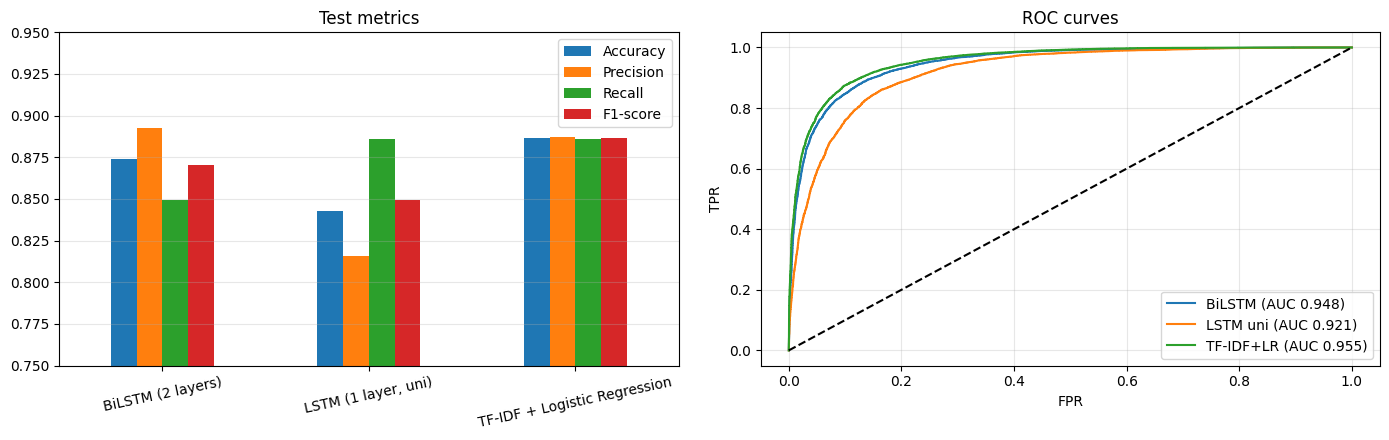

In [9]:
# ============================================================
# CELL 9: Comparison with baselines
# ============================================================
# Unidirectional 1-layer LSTM
model_uni = LSTMClassifier(len(itos), layers=1, bidirectional=False).to(device)
hist_uni = train_model(model_uni, 'LSTM-1L-uni')
prob_uni = predict_proba(model_uni, Xte, Lte)

# TF-IDF + Logistic Regression
stop = set(ENGLISH_STOP_WORDS) | {'br', 'movie', 'film', 'one', 'like',
                                  "it's", "i'm", "don't", "didn't", 'just', 'really'}
def clean_tfidf(text):
    return ' '.join(w for w in clean(text) if w not in stop and w.isalpha())

tfidf = TfidfVectorizer(token_pattern=r'\b\w+\b', lowercase=False,
                        ngram_range=(1, 2), max_features=100000, sublinear_tf=True)
Xtr_tf = tfidf.fit_transform([clean_tfidf(t) for t in tr_texts])
Xte_tf = tfidf.transform([clean_tfidf(t) for t in test_texts])
lr = LogisticRegression(max_iter=1000, C=4).fit(Xtr_tf, tr_y)
prob_lr = lr.predict_proba(Xte_tf)[:, 1]

compare = pd.DataFrame({
    'BiLSTM (2 layers)': metrics(test_labels, prob_main),
    'LSTM (1 layer, uni)': metrics(test_labels, prob_uni),
    'TF-IDF + Logistic Regression': metrics(test_labels, prob_lr)
}).T
compare.to_csv(f'{OUTPUT_DIR}/model_comparison.csv')
display(compare.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
compare[['Accuracy', 'Precision', 'Recall', 'F1-score']].plot.bar(
    ax=ax[0], rot=12, ylim=(0.75, 0.95))
ax[0].set_title('Test metrics'); ax[0].grid(axis='y', alpha=.3)
for nm, p in [('BiLSTM', prob_main), ('LSTM uni', prob_uni), ('TF-IDF+LR', prob_lr)]:
    f, t, _ = roc_curve(test_labels, p)
    ax[1].plot(f, t, label=f'{nm} (AUC {roc_auc_score(test_labels, p):.3f})')
ax[1].plot([0, 1], [0, 1], 'k--')
ax[1].set_title('ROC curves'); ax[1].set_xlabel('FPR'); ax[1].set_ylabel('TPR')
ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/comparison.png', dpi=130)
plt.show()

## 10. Error Analysis

The predictions from the main BiLSTM model are compared with the actual test labels to identify incorrectly classified reviews.

A small set of misclassified examples is selected for inspection, along with each model prediction and its estimated probability of the positive class. The complete error summary is written to a text file. This analysis can help identify examples where sentiment is difficult to classify from the review text.


In [10]:
# ============================================================
# CELL 10: Error analysis
# ============================================================
wrong = np.where(pred_main != test_labels)[0]
conf_err = wrong[np.argsort(-np.abs(prob_main[wrong] - 0.5))][:6]

with open(f'{OUTPUT_DIR}/error_analysis.txt', 'w') as f:
    for i in conf_err:
        true_l = 'positive' if test_labels[i] else 'negative'
        pred_l = 'positive' if pred_main[i] else 'negative'
        line = (f'TRUE: {true_l} | PREDICTED: {pred_l} '
                f'(P(pos) = {prob_main[i]:.3f})\n'
                f'   {re.sub(r"<br\s*/?>", " ", test_texts[i])[:450].strip()}...\n\n')
        print(line); f.write(line)
    summary = (f'Total misclassified: {len(wrong)} of {len(test_labels)} '
               f'({len(wrong)/len(test_labels)*100:.1f}%)\n')
    print(summary); f.write(summary)


TRUE: negative | PREDICTED: positive (P(pos) = 1.000)
   I went to see this 3 nights ago here in Cork, Ireland. It was the world premiere of it, in the tiny cinema in the Triskel Arts Centre as part of the Cork Film Festival.  I found "Strange Fruit" to be an excellent movie. It is a bit rough around the edges, but for a low-budget movie that is to be expected! In general the acting (particularly from the main lead Kent Faulcon) is wonderful, the cinematography and direction excellent, and the script h...


TRUE: negative | PREDICTED: positive (P(pos) = 1.000)
   I must say I was disappointed with this film. Although it is well acted and directed, the underlying story simply plods along too slowly.  Granted, in another mood I would have liked it better. I did chuckle a lot, but rarely laughed out loud; and there was actually a sense of suspense to discover who won. But in contrast to another movie that my wife picked up the same day (one neither of us had heard of before) this one pale

## 11. Word Embedding Analysis and PCA Visualization

The embedding vectors learned by the BiLSTM model are normalized and used to calculate cosine-similarity-based nearest neighbours for selected sentiment-related words.

Principal Component Analysis (PCA) is then used to project selected word embeddings into two dimensions. The resulting plot provides a visual inspection of how the selected words are positioned in the learned embedding space. The visualization is exploratory and should not be interpreted as a complete representation of the model's language understanding.


excellent  -> pet, jerome, inexperienced, spellbinding, radar, magnificent, sleeper

terrible   -> 1932, adequate, zombies, characters', writings, starts, dull

boring     -> grades, awful, cautionary, intelligence, unrealistic, snicker, report

funny      -> tied, drama, challenger, yours, situation, creepshow, adaptation

waste      -> disappointing, pretentious, disappointment, nada, toes, crackers, schizophrenia

brilliant  -> uber, aviation, serrault, reiser, perfectly, king, wizards



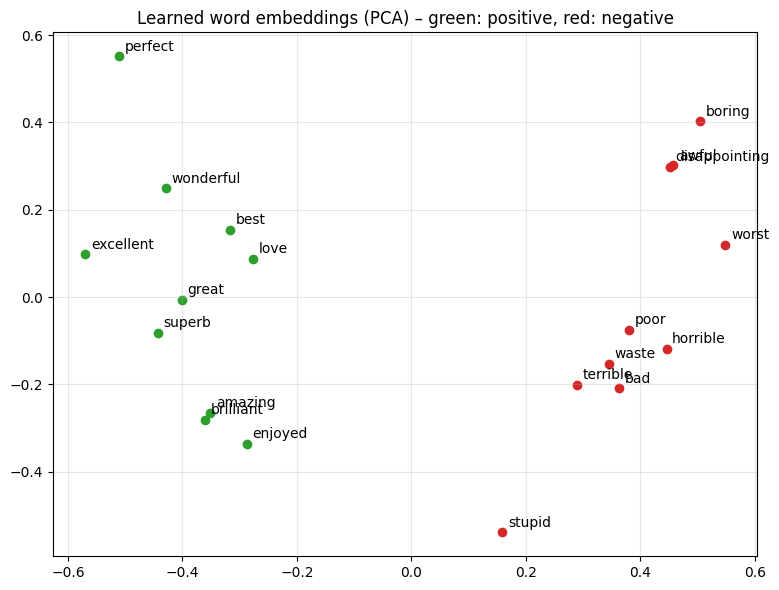

In [11]:
# ============================================================
# CELL 11: Visualize learned embeddings (PCA)
# ============================================================
import torch.nn.functional as F
from sklearn.decomposition import PCA

W = F.normalize(model.embedding.weight.detach().cpu(), dim=1)
def neighbours(word, k=7):
    if word not in stoi: return []
    sims = W @ W[stoi[word]]
    return [itos[i] for i in sims.argsort(descending=True)[1:k + 1].tolist()]

with open(f'{OUTPUT_DIR}/embedding_neighbours.txt', 'w') as f:
    for w in ['excellent', 'terrible', 'boring', 'funny', 'waste', 'brilliant']:
        line = f'{w:10s} -> {", ".join(neighbours(w))}\n'
        print(line); f.write(line)

words = ['excellent', 'great', 'wonderful', 'amazing', 'brilliant', 'perfect',
         'love', 'best', 'enjoyed', 'superb',
         'terrible', 'awful', 'worst', 'boring', 'bad', 'waste',
         'poor', 'horrible', 'stupid', 'disappointing']
words = [w for w in words if w in stoi]
if len(words) >= 2:
    P2 = PCA(n_components=2).fit_transform(W[[stoi[w] for w in words]].numpy())
    plt.figure(figsize=(8, 6))
    pos = {'excellent','great','wonderful','amazing','brilliant','perfect',
           'love','best','enjoyed','superb'}
    for (x, y), w in zip(P2, words):
        c = 'tab:green' if w in pos else 'tab:red'
        plt.scatter(x, y, c=c)
        plt.annotate(w, (x, y), xytext=(4, 4), textcoords='offset points')
    plt.title('Learned word embeddings (PCA) – green: positive, red: negative')
    plt.grid(alpha=.3)
    plt.tight_layout()
    plt.savefig(f'{OUTPUT_DIR}/embeddings.png', dpi=130)
    plt.show()
else:
    print('Not enough selected words are present in the vocabulary for PCA.')


## 12. Results, Discussion, and Conclusion

### BiLSTM test performance

The two-layer Bidirectional LSTM achieved **87.37% test accuracy**, **89.26% precision**, **84.96% recall**, **87.06% F1-score**, and **0.9479 ROC-AUC** on the 25,000-review test set. The positive-class precision is higher than its recall, which means the model is more reliable when it predicts a positive review than it is at finding every positive review.

The confusion matrix contains **11,222 true negatives**, **1,278 false positives**, **1,880 false negatives**, and **10,620 true positives**. In total, 3,158 of the 25,000 test reviews were misclassified (approximately 12.6%).

### Comparison with the baseline models

| Model | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| BiLSTM (2 layers) | 0.8737 | 0.8926 | 0.8496 | 0.8706 | 0.9479 |
| LSTM (1 layer, unidirectional) | 0.8428 | 0.8157 | 0.8858 | 0.8493 | 0.9207 |
| TF-IDF + Logistic Regression | 0.8866 | 0.8871 | 0.8860 | 0.8865 | 0.9551 |

The BiLSTM outperformed the unidirectional LSTM in accuracy, precision, F1-score, and ROC-AUC, while the unidirectional model had higher recall. The TF-IDF + Logistic Regression baseline achieved the highest accuracy, recall, F1-score, and ROC-AUC; the BiLSTM achieved the highest precision. This shows that a traditional TF-IDF model is a strong baseline for this dataset and that the neural model is not the best-performing model on every metric.

### Observations and limitations

- The training and validation curves show improving performance over the eight training epochs. The final held-out test accuracy is lower than the final training and validation accuracies, indicating a modest generalization gap.
- Reviews are truncated to 300 tokens. The training-partition length analysis indicates that approximately 23% of reviews exceed this limit, so some review context may be lost.
- The error examples show that reviews containing strongly positive words can still have an overall negative sentiment. Mixed opinions, contrastive statements, and context can therefore lead to confident errors.
- The PCA plot uses a selected set of positive and negative words, so it is an exploratory visualization rather than proof that the entire vocabulary is cleanly separated. Some nearest-neighbour embedding results are not semantically coherent.

### Conclusion

The experiment successfully implemented a binary text-classification model using a trainable Embedding layer and a two-layer Bidirectional LSTM network. The model was trained on the IMDB training partition and evaluated on a separate test partition using accuracy, precision, recall, F1-score, ROC-AUC, a classification report, and confusion matrices. The BiLSTM achieved **87.37% test accuracy** and **0.9479 ROC-AUC**. Therefore, the practical requirement of building and evaluating an Embedding-LSTM text classifier is satisfied. The comparison also demonstrates why multiple metrics and a traditional baseline are useful when assessing a classification model.


## 13. Saving the Trained Model and Vocabulary

The trained BiLSTM parameters are saved as `bilstm_model.pt`. The vocabulary mappings and maximum sequence length are saved separately in `vocab.pt`.

Both files are required components for reusing the trained model for later inference. The model architecture and matching hyperparameters must also be recreated when loading the saved state dictionary.


In [12]:
# ============================================================
# CELL 13: Save model weights
# ============================================================
torch.save(model.state_dict(), f'{OUTPUT_DIR}/bilstm_model.pt')
torch.save({'stoi': stoi, 'itos': itos, 'MAX_LEN': MAX_LEN},
           f'{OUTPUT_DIR}/vocab.pt')
print('Model & vocab saved.')


Model & vocab saved.


## 14. Exporting Experimental Results

This section collects the generated files from `/content/results/` and packages them into a compressed archive named `results.zip`.

The archive includes the exploratory-data-analysis plot, training curves, evaluation and comparison plots, classification metrics, error-analysis text, embedding analysis, and saved model files. In Google Colab, the final cell initiates the download of the ZIP archive.


In [13]:
# ============================================================
# CELL 14: Create ZIP and download
# ============================================================
ZIP_PATH = '/content/results.zip'
with zipfile.ZipFile(ZIP_PATH, 'w', zipfile.ZIP_DEFLATED) as zf:
    for root, _, files in os.walk(OUTPUT_DIR):
        for file in files:
            path = os.path.join(root, file)
            zf.write(path, os.path.relpath(path, OUTPUT_DIR))

print(f'\nZIP created: {ZIP_PATH}')
print('Contents:')
with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    for info in zf.infolist():
        print(f'  {info.filename:30s} {info.file_size:>10d} bytes')

from google.colab import files
files.download(ZIP_PATH)
print('\nDownload started. If not, run this cell again.')



ZIP created: /content/results.zip
Contents:
  classification_report.txt             326 bytes
  training_curves.png                 89382 bytes
  comparison.png                     102669 bytes
  bilstm_model.pt                  12882831 bytes
  embeddings.png                      56845 bytes
  error_analysis.txt                   2673 bytes
  embedding_neighbours.txt              489 bytes
  model_comparison.csv                  321 bytes
  vocab.pt                           498401 bytes
  evaluation.png                      75187 bytes
  eda_overview.png                    52082 bytes
  test_metrics.csv                       97 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Download started. If not, run this cell again.
